In [ ]:
# Mount Drive & Extract
from google.colab import drive
drive.mount('/content/drive')

!cp "/content/drive/MyDrive/IEMOCAPdataset/IEMOCAP_full_release_withoutVideos.tar.gz" /content/
!tar -xzf /content/IEMOCAP_full_release_withoutVideos.tar.gz -C /content/

Mounted at /content/drive


In [ ]:
# Verify extraction by listing contents
print("\nVerifying IEMOCAP extraction:")
!ls -R /content/IEMOCAP_full_release | head -n 50
!echo "... (truncated)"


Verifying IEMOCAP extraction:
/content/IEMOCAP_full_release:
Documentation
README.txt
README.txt~
Session1
Session2
Session3
Session4
Session5

/content/IEMOCAP_full_release/Documentation:
corpus.dic
FIVE_face_markers2.png
HumaineInfo.txt
phonemes.txt
timeinfo.txt

/content/IEMOCAP_full_release/Session1:
dialog
sentences

/content/IEMOCAP_full_release/Session1/dialog:
avi
EmoEvaluation
lab
MOCAP_hand
MOCAP_head
MOCAP_rotated
transcriptions
wav

/content/IEMOCAP_full_release/Session1/dialog/avi:
DivX

/content/IEMOCAP_full_release/Session1/dialog/avi/DivX:
Ses01F_impro01.avi
Ses01F_impro02.avi
Ses01F_impro03.avi
Ses01F_impro04.avi
Ses01F_impro05.avi
Ses01F_impro06.avi
Ses01F_impro07.avi
Ses01F_script01_1.avi
Ses01F_script01_2.avi
Ses01F_script01_3.avi
Ses01F_script02_1.avi
Ses01F_script02_2.avi
Ses01F_script03_1.avi
Ses01F_script03_2.avi
Ses01M_impro01.avi
... (truncated)


In [ ]:
!ls /content/IEMOCAP_full_release/Session1/dialog/wav/

Ses01F_impro01.wav     Ses01F_script02_1.wav  Ses01M_impro07.wav
Ses01F_impro02.wav     Ses01F_script02_2.wav  Ses01M_script01_1.wav
Ses01F_impro03.wav     Ses01F_script03_1.wav  Ses01M_script01_2.wav
Ses01F_impro04.wav     Ses01F_script03_2.wav  Ses01M_script01_3.wav
Ses01F_impro05.wav     Ses01M_impro01.wav     Ses01M_script02_1.wav
Ses01F_impro06.wav     Ses01M_impro02.wav     Ses01M_script02_2.wav
Ses01F_impro07.wav     Ses01M_impro03.wav     Ses01M_script03_1.wav
Ses01F_script01_1.wav  Ses01M_impro04.wav     Ses01M_script03_2.wav
Ses01F_script01_2.wav  Ses01M_impro05.wav
Ses01F_script01_3.wav  Ses01M_impro06.wav


In [ ]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [ ]:
import os
import pandas as pd

data = []

sessions = [s for s in os.listdir(dataset_path) if s.startswith("Session")]

for session in sessions:
    emo_path = os.path.join(dataset_path, session, "dialog", "EmoEvaluation")

    for file in os.listdir(emo_path):
        if file.endswith(".txt"):
            file_path = os.path.join(emo_path, file)

            with open(file_path, "r") as f:
                lines = f.readlines()

            for line in lines:
                if line.startswith("["):
                    parts = line.strip().split("\t")

                    if len(parts) < 3:
                        continue

                    utt_id = parts[1]
                    emotion = parts[2]

                    # conversation_id
                    conv_id = "_".join(utt_id.split("_")[:2])

                    data.append([conv_id, utt_id, emotion])

df = pd.DataFrame(data, columns=["conversation_id", "utterance_id", "emotion"])

print("Total rows:", len(df))
print(df.head())

Total rows: 10039
   conversation_id          utterance_id emotion
0  Ses03M_impro08b  Ses03M_impro08b_F000     xxx
1  Ses03M_impro08b  Ses03M_impro08b_F001     fru
2  Ses03M_impro08b  Ses03M_impro08b_F002     fru
3  Ses03M_impro08b  Ses03M_impro08b_F003     fru
4  Ses03M_impro08b  Ses03M_impro08b_F004     fru


In [ ]:
#  IMPROVED MULTIMODAL EMOTION MODEL

!pip install transformers librosa imbalanced-learn -q

import os, glob
import numpy as np
import librosa
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from transformers import AutoTokenizer, AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# LOAD DATA (same as yours)
DATA_PATH = "/content/IEMOCAP_full_release"
valid_emotions = ["ang","hap","sad","neu","exc"]

wav_paths, texts, labels = [], [], []

for session in range(1,6):
    session_path = os.path.join(DATA_PATH, f"Session{session}")
    wav_files = glob.glob(os.path.join(session_path, "**/*.wav"), recursive=True)

    for wav_file in wav_files:
        file_id = os.path.basename(wav_file).replace(".wav","")
        parts = file_id.split("_")

        ann_name = "_".join(parts[:2]) + ".txt" if "impro" in file_id else "_".join(parts[:3]) + ".txt"
        ann_path = os.path.join(session_path,"dialog","EmoEvaluation",ann_name)
        trans_path = os.path.join(session_path,"dialog","transcriptions",ann_name)

        if not os.path.exists(ann_path) or not os.path.exists(trans_path):
            continue

        emotion = None
        with open(ann_path) as f:
            for line in f:
                if file_id in line:
                    emotion = line.strip().split()[4]
                    break

        if emotion not in valid_emotions:
            continue
        if emotion == "exc":
            emotion = "hap"

        text = ""
        with open(trans_path) as f:
            for line in f:
                if file_id in line:
                    text = " ".join(line.strip().split()[2:])
                    break

        if text == "":
            continue

        wav_paths.append(wav_file)
        texts.append(text)
        labels.append(emotion)

print("Samples:", len(wav_paths))

# AUDIO FEATURES
def extract_logmel(path):
    y, sr = librosa.load(path, sr=16000)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
    return librosa.power_to_db(mel)

def pad_truncate(x, max_len=128):
    if x.shape[1] > max_len:
        return x[:, :max_len]
    else:
        return np.pad(x, ((0,0),(0,max_len - x.shape[1])))

audio_features = []

for p in tqdm(wav_paths):
    try:
        feat = pad_truncate(extract_logmel(p))
        if feat.shape == (64,128):
            audio_features.append(feat)
    except:
        continue

X_audio = np.stack(audio_features)[:,None,:,:]

# TEXT FEATURES
tokenizer = AutoTokenizer.from_pretrained("distilroberta-base")
text_model = AutoModel.from_pretrained("distilroberta-base").to(device)
text_model.eval()

def extract_text(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True).to(device)
    with torch.no_grad():
        out = text_model(**inputs)
    return out.last_hidden_state[:,0,:].cpu().numpy().flatten()

X_text = np.stack([extract_text(t) for t in texts[:len(X_audio)]])

# LABELS
le = LabelEncoder()
y = le.fit_transform(labels[:len(X_text)])

# SPLIT
Xa_train, Xa_test, Xt_train, Xt_test, y_train, y_test = train_test_split(
    X_audio, X_text, y, test_size=0.2, stratify=y, random_state=42
)

# CORRECT OVERSAMPLING (IMPORTANT FIX)
from imblearn.over_sampling import RandomOverSampler

Xa_flat = Xa_train.reshape(len(Xa_train), -1)
combined = np.hstack([Xa_flat, Xt_train])

ros = RandomOverSampler()
combined_res, y_train = ros.fit_resample(combined, y_train)

Xa_train = combined_res[:,:Xa_flat.shape[1]].reshape(-1,1,64,128)
Xt_train = combined_res[:,Xa_flat.shape[1]:]

# NORMALIZATION (AUDIO + TEXT)
scaler_a = StandardScaler()
scaler_t = StandardScaler()

Xa_train = scaler_a.fit_transform(Xa_train.reshape(len(Xa_train), -1)).reshape(-1,1,64,128)
Xa_test = scaler_a.transform(Xa_test.reshape(len(Xa_test), -1)).reshape(-1,1,64,128)

Xt_train = scaler_t.fit_transform(Xt_train)
Xt_test = scaler_t.transform(Xt_test)

# MODEL IMPROVED
class AudioModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1,32,3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.lstm = nn.LSTM(64*16,128,batch_first=True,bidirectional=True)

    def forward(self,x):
        x = self.cnn(x)
        b,c,f,t = x.shape
        x = x.permute(0,3,1,2).reshape(b,t,-1)

        out,_ = self.lstm(x)
        return torch.mean(out, dim=1)

class TextModel(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(dim,256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

    def forward(self,x):
        return self.fc(x)

class FusionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.audio = AudioModel()
        self.text = TextModel(Xt_train.shape[1])

        self.gate = nn.Linear(256+256,256)

        self.classifier = nn.Sequential(
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128,len(le.classes_))
        )

    def forward(self,a,t):
        a = self.audio(a)
        t = self.text(t)

        fusion = torch.cat([a,t],dim=1)
        gate = torch.sigmoid(self.gate(fusion))

        fused = gate * a + (1-gate) * t
        return self.classifier(fused)

model = FusionModel().to(device)

# TRAIN
class_weights = torch.tensor(
    compute_class_weight('balanced', classes=np.unique(y_train), y=y_train),
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.5)

train_data = torch.utils.data.TensorDataset(
    torch.tensor(Xa_train, dtype=torch.float32),
    torch.tensor(Xt_train, dtype=torch.float32),
    torch.tensor(y_train)
)

loader = torch.utils.data.DataLoader(train_data, batch_size=16, shuffle=True)

for epoch in range(12):
    model.train()
    total_loss = 0

    for xa, xt, yb in loader:
        xa, xt, yb = xa.to(device), xt.to(device), yb.to(device)

        out = model(xa, xt)
        loss = criterion(out, yb)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item()

    scheduler.step()
    print(f"Epoch {epoch+1} Loss: {total_loss:.4f}")

# EVALUATION
model.eval()

with torch.no_grad():
    preds = torch.argmax(
        model(
            torch.tensor(Xa_test, dtype=torch.float32).to(device),
            torch.tensor(Xt_test, dtype=torch.float32).to(device)
        ), dim=1
    ).cpu().numpy()

print("\nAccuracy:", accuracy_score(y_test, preds))
print(classification_report(y_test, preds))

Samples: 5621


100%|██████████| 5621/5621 [01:39<00:00, 56.33it/s] 


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: distilroberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1 Loss: 390.2056
Epoch 2 Loss: 302.5715
Epoch 3 Loss: 258.5859
Epoch 4 Loss: 230.8881
Epoch 5 Loss: 214.4284
Epoch 6 Loss: 204.9819
Epoch 7 Loss: 188.0124
Epoch 8 Loss: 181.0705
Epoch 9 Loss: 174.7641
Epoch 10 Loss: 167.5229
Epoch 11 Loss: 159.6630
Epoch 12 Loss: 157.0536

Accuracy: 0.7413333333333333
              precision    recall  f1-score   support

           0       0.74      0.82      0.78       223
           1       0.76      0.67      0.71       331
           2       0.73      0.69      0.71       351
           3       0.74      0.85      0.79       220

    accuracy                           0.74      1125
   macro avg       0.74      0.76      0.75      1125
weighted avg       0.74      0.74      0.74      1125




Sample Conversation IDs:
['Ses01F_impro01' 'Ses01F_impro02' 'Ses01F_impro03' 'Ses01F_impro04'
 'Ses01F_impro05' 'Ses01F_impro06' 'Ses01F_impro07' 'Ses01F_script01'
 'Ses01F_script02' 'Ses01F_script03']

Enter conversation ID: Ses01F_impro02


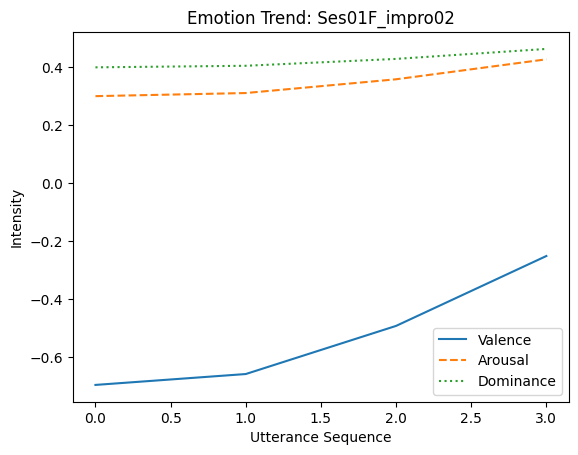


CONCLUSION:
Positive Shift
Stable Behavior


In [ ]:
# 🔥 EMOTION TREND ANALYSIS

import pandas as pd
import re
from scipy.ndimage import gaussian_filter1d

# Recreate SAME split to get test paths (aligned)
_, path_test = train_test_split(
    wav_paths[:len(X_audio)],
    test_size=0.2,
    stratify=y,
    random_state=42
)

pred_labels = le.inverse_transform(preds)

# BUILD RECORDS
records = []

for idx, (path, pred) in enumerate(zip(path_test, pred_labels)):
    filename = os.path.basename(path).replace(".wav","")
    parts = filename.split("_")

    # Conversation ID (dialog)
    conv_id = "_".join(parts[:2])

    # Utterance order
    match = re.search(r'(\d+)$', filename)
    utt_id = int(match.group(1)) if match else idx

    records.append({
        "conversation_id": conv_id,
        "utterance_id": utt_id,
        "emotion_label": pred
    })

df = pd.DataFrame(records)
df = df.sort_values(by=["conversation_id","utterance_id"])

# VAD MAPPING
VAD_MAP = {
    "hap": (0.8,0.7,0.6),
    "sad": (-0.7,0.3,0.4),
    "ang": (-0.6,0.8,0.7),
    "neu": (0.0,0.5,0.5)
}

print("\nSample Conversation IDs:")
print(df["conversation_id"].unique()[:10])

cid = input("\nEnter conversation ID: ")

subset = df[df["conversation_id"] == cid]

# TREND COMPUTATION
if len(subset) > 0:

    emotions = subset["emotion_label"].tolist()

    # Convert to VAD
    vad = np.array([VAD_MAP[e] for e in emotions if e in VAD_MAP])

    if len(vad) == 0:
        print("No valid emotions for VAD mapping")
    else:
        val = gaussian_filter1d(vad[:,0], 1)
        aro = gaussian_filter1d(vad[:,1], 1)
        dom = gaussian_filter1d(vad[:,2], 1)

        # Plot
        plt.figure()
        plt.plot(val, label="Valence")
        plt.plot(aro, linestyle="--", label="Arousal")
        plt.plot(dom, linestyle=":", label="Dominance")

        plt.legend()
        plt.title(f"Emotion Trend: {cid}")
        plt.xlabel("Utterance Sequence")
        plt.ylabel("Intensity")
        plt.show()

                # FINAL INTERPRETATION
                trend = val[-1] - val[0]
        variance = np.var(val)

        print("\nCONCLUSION:")

        if trend > 0.2:
            print("Positive Shift")
        elif trend < -0.2:
            print("Negative Shift")
        else:
            print("Stable Emotion")

        if variance > 0.5:
            print("High Fluctuation")
        else:
            print("Stable Behavior")

else:
    print("Conversation not found")